In [122]:
# import
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns
import time
from scipy.stats import norm


In [123]:
# timestamp
ts = time.strftime("%Y%m%d_%H%M%S")

In [124]:
# load data
df_raw = pd.read_csv("../data/labjs_data.csv")

# check
df_raw.head(10)

,url,meta,sender,sender_type,sender_id,Unnamed: 5,ended_on,duration,time_run,time_render,...,response_action,p_sent,p_cond,p_type,correctResponse,correct,sent,cond,type,studyResultID
0,NaN,NaN,prac_instr,canvas.Screen,1,NaN,response,2935.0,44536.0,44540.0,...,keypress,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,631
1,NaN,NaN,p_fx,canvas.Screen,2_0_0,NaN,timeout,333.0,47417.0,47418.0,...,NaN,Katten er lille og sød,g,1.0,NaN,NaN,NaN,NaN,NaN,631
2,NaN,NaN,p_stimuli,canvas.Screen,2_0_1,NaN,timeout,450.0,47753.0,47752.0,...,NaN,Katten er lille og sød,g,1.0,NaN,NaN,NaN,NaN,NaN,631
3,NaN,NaN,p_mask,canvas.Screen,2_0_2,NaN,response,3547.0,48205.0,48203.0,...,keypress(a),Katten er lille og sød,g,1.0,g,False,NaN,NaN,NaN,631
4,NaN,NaN,p_fb,canvas.Screen,2_0_3,NaN,timeout,200.0,51674.0,51675.0,...,NaN,Katten er lille og sød,g,1.0,NaN,NaN,NaN,NaN,NaN,631
5,NaN,NaN,p_trial,flow.Sequence,2_0,NaN,completion,4449.0,47417.0,47418.0,...,NaN,Katten er lille og sød,g,1.0,NaN,NaN,NaN,NaN,NaN,631
6,NaN,NaN,p_fx,canvas.Screen,2_1_0,NaN,timeout,316.0,51886.0,51885.0,...,NaN,Hans fugle er meget fine,g,1.0,NaN,NaN,NaN,NaN,NaN,631
7,NaN,NaN,p_stimuli,canvas.Screen,2_1_1,NaN,timeout,251.0,52204.0,52202.0,...,NaN,Hans fugle er meget fine,g,1.0,NaN,NaN,NaN,NaN,NaN,631
8,NaN,NaN,p_mask,canvas.Screen,2_1_2,NaN,response,2296.0,52453.0,52452.0,...,keypress(a),Hans fugle er meget fine,g,1.0,g,False,NaN,NaN,NaN,631
9,NaN,NaN,p_fb,canvas.Screen,2_1_3,NaN,timeout,199.0,54671.0,54674.0,...,NaN,Hans fugle er meget fine,g,1.0,NaN,NaN,NaN,NaN,NaN,631


In [125]:
# define function for initial filtering
def filter_data(df):
    # rename relevant columns
    df = df.rename(columns = {"studyResultID": "subject",
                              "sender" : "screen_type",
                              "duration" : "screen_duration",
                              "sent" : "sequence",
                              "cond": "condition",
                              "correct": "accuracy"})
    # filter to relevant columns
    df = df[["subject", "screen_type", "screen_duration", "sequence", 
             "condition", "accuracy"]]
    # filter out instr screens, practice rounds, etc by keeping only rows with a non-practice sequence
    df = df.dropna(subset = ["sequence"])
    return df



In [126]:
# apply filter function to raw data
df_filtered = filter_data(df_raw)

# check
df_filtered.head(10)

,subject,screen_type,screen_duration,sequence,condition,accuracy
23,631,fx,333.0,Han vil løbet i dag,u,NaN
24,631,stimuli,50.0,Han vil løbet i dag,u,NaN
25,631,mask,3504.0,Han vil løbet i dag,u,False
26,631,fb,200.0,Han vil løbet i dag,u,NaN
27,631,trial,4000.0,Han vil løbet i dag,u,NaN
28,631,fx,333.0,Hunden bed de små barn,u,NaN
29,631,stimuli,51.0,Hunden bed de små barn,u,NaN
30,631,mask,1155.0,Hunden bed de små barn,u,False
31,631,fb,200.0,Hunden bed de små barn,u,NaN
32,631,trial,1651.0,Hunden bed de små barn,u,NaN


In [127]:
# define function for compressing data to one row per trial
def compress_data(trial):
    # get presentation duration as logged on stimuli screen
    pres_dur = trial.loc[trial["screen_type"] == "stimuli", 
                         "screen_duration"].values[0]
    # round presentation duration to nearest 50 (raw data is off due to screen refresh rate)
    pres_dur = round(pres_dur / 50) * 50
    # calculate RT as sum of raw presentation & mask duration
    rt = trial.loc[trial["screen_type"].isin(["stimuli", "mask"]), 
                   "screen_duration"].sum()
    # get accuracy as logged on mask screen
    acc = trial.loc[trial["screen_type"] == "mask", 
                    "accuracy"].values[0]
    # get grammaticality condition (invariant for the trial)
    cond = trial["condition"].values[0]
    # return
    return pd.Series({"presentation_duration": pres_dur,
                      "RT": rt,
                      "condition": cond,
                      "accuracy": acc})

In [128]:
# apply compression function at trial level as defined by subject & sequence
df_compressed = df_filtered.groupby(["subject", "sequence"]).apply(compress_data).reset_index()

# check
df_compressed.head(10)

,subject,sequence,presentation_duration,RT,condition,accuracy
0,631,Bilen er stor og grim,350,1883.0,g,True
1,631,Bilen ramte den lille pige,450,1706.0,g,True
2,631,De driftig vand til maden,100,1436.0,u,False
3,631,De drikker kaffe på altanen,200,3330.0,g,False
4,631,De en fik ny hund,50,1072.0,u,False
5,631,De gik en lang tur,350,1640.0,g,True
6,631,De kan måske lide ham,300,2044.0,g,True
7,631,De skal handle i Tyskland,350,1349.0,g,True
8,631,De spisede mad i går,400,1547.0,u,False
9,631,De vil ikke spiser mad,400,2091.0,u,True


In [129]:
# define function for excluding participants and sequences with low mean accuracy
def filter_accuracy(df, threshold = 0.5):
    # participants
    mean_subject_acc = df.groupby("subject")["accuracy"].mean() 
    valid_subjects = mean_subject_acc[mean_subject_acc >= threshold].index
    df = df[df["subject"].isin(valid_subjects)]
    # sequences
    mean_sequence_acc = df.groupby("sequence")["accuracy"].mean()
    valid_sequences = mean_sequence_acc[mean_sequence_acc >= threshold].index
    df = df[df["sequence"].isin(valid_sequences)]
    return df

In [130]:
# apply accuracy filter function
df_clean = filter_accuracy(df_compressed, 0.0)

# check
df_clean.head(10)

,subject,sequence,presentation_duration,RT,condition,accuracy
0,631,Bilen er stor og grim,350,1883.0,g,True
1,631,Bilen ramte den lille pige,450,1706.0,g,True
2,631,De driftig vand til maden,100,1436.0,u,False
3,631,De drikker kaffe på altanen,200,3330.0,g,False
4,631,De en fik ny hund,50,1072.0,u,False
5,631,De gik en lang tur,350,1640.0,g,True
6,631,De kan måske lide ham,300,2044.0,g,True
7,631,De skal handle i Tyskland,350,1349.0,g,True
8,631,De spisede mad i går,400,1547.0,u,False
9,631,De vil ikke spiser mad,400,2091.0,u,True


In [131]:
# define function for calculating average accuracy
def calculate_accuracy(group):
    acc = group["accuracy"].mean()
    return pd.Series({"accuracy": acc})

In [132]:
# apply function for calculating average accuracy at subject&presentation duration&condition level
df_acc = df_clean.groupby(["subject", "presentation_duration", "condition"]).apply(calculate_accuracy).reset_index()

# check
df_acc.head(10)

,subject,presentation_duration,condition,accuracy
0,631,50,g,0.500000
1,631,50,u,0.428571
2,631,100,g,0.800000
3,631,100,u,0.166667
4,631,150,g,1.000000
5,631,150,u,0.250000
6,631,200,g,0.666667
7,631,200,u,0.500000
8,631,250,g,1.000000
9,631,250,u,0.500000


In [133]:
# define function for determining response type outcome
def get_outcome(df):
    # set up confusion matrix for possible outcomes
    matrix = [(df["condition"] == "g") & (df["accuracy"] == True),   # hit
              (df["condition"] == "g") & (df["accuracy"] == False),  # miss
              (df["condition"] == "u") & (df["accuracy"] == True),   # correct rejection
              (df["condition"] == "u") & (df["accuracy"] == False)]  # false alarm
    # define outcome labels
    labels = ["hit", "miss", "CR", "FA"]
    # select label for each row and add to new outcome column
    df["outcome"] = np.select(matrix, labels, default = "unknown")
    return df

In [134]:
# apply outcome determining function
df_outcomes = get_outcome(df_clean) 

# check
df_outcomes.head(10)

,subject,sequence,presentation_duration,RT,condition,accuracy,outcome
0,631,Bilen er stor og grim,350,1883.0,g,True,hit
1,631,Bilen ramte den lille pige,450,1706.0,g,True,hit
2,631,De driftig vand til maden,100,1436.0,u,False,FA
3,631,De drikker kaffe på altanen,200,3330.0,g,False,miss
4,631,De en fik ny hund,50,1072.0,u,False,FA
5,631,De gik en lang tur,350,1640.0,g,True,hit
6,631,De kan måske lide ham,300,2044.0,g,True,hit
7,631,De skal handle i Tyskland,350,1349.0,g,True,hit
8,631,De spisede mad i går,400,1547.0,u,False,FA
9,631,De vil ikke spiser mad,400,2091.0,u,True,CR


In [135]:
# define function for calculating mean RTs for each response type/outcome
def calculate_rt(df):
    #average across trials, then participants, then durations for each response type
    return (df.groupby(["subject", "presentation_duration", "outcome"])["RT"].mean().reset_index()
    .groupby(["presentation_duration", "outcome"])["RT"].mean().reset_index()
    .groupby("outcome")["RT"].mean().reset_index())

In [136]:
# apply RT calculation function
df_rt = calculate_rt(df_outcomes)
df_rt.to_csv((os.path.join("..", "out", f"RT_summary_{ts}.csv")), sep = "\t", index = False)

# check
df_rt

,outcome,RT
0,CR,1811.358358
1,FA,1736.212251
2,hit,1549.761472
3,miss,1755.518573


In [137]:
# define function for calculating hit & false alarm rates
def calculate_rates(group):
    # count outcomes
    hits = (group["outcome"] == "hit").sum()
    misses = (group["outcome"] == "miss").sum()
    CRs = (group["outcome"] == "CR").sum()
    FAs = (group["outcome"] == "FA").sum()
    # calculate hit & FA rates, accounting for possible zero values
    if (hits + misses) > 0:
        hit_rate = hits / (hits + misses)
    else:
        hit_rate = np.nan
    if (CRs + FAs) > 0:
        FA_rate = FAs / (CRs + FAs)
    else:
        FA_rate = np.nan
    # enforce shifted boundaries or the math won't math
    if hit_rate == 1:
        hit_rate = 0.99
    elif hit_rate == 0:
        hit_rate = 0.01
    if FA_rate == 1:
        FA_rate = 0.99
    elif FA_rate == 0:
        FA_rate = 0.01
    # return
    return pd.Series({"hit_rate" : hit_rate,
                      "FA_rate" : FA_rate})

In [138]:
# apply hit & false alarm rate calculation function for each participant at each presentation duration
df_rated = df_outcomes.groupby(["subject", "presentation_duration"]).apply(calculate_rates).reset_index()

# check
df_rated.head(10)

,subject,presentation_duration,hit_rate,FA_rate
0,631,50,0.500000,0.571429
1,631,100,0.800000,0.833333
2,631,150,0.990000,0.750000
3,631,200,0.666667,0.500000
4,631,250,0.990000,0.500000
5,631,300,0.990000,0.010000
6,631,350,0.990000,0.250000
7,631,400,0.500000,0.250000
8,631,450,0.990000,0.714286
9,631,500,0.990000,0.500000


In [139]:
# define function for calculating sensitivity d' and bias c (SDT measures)
def calculate_sdt(df):
    # get z scores
    z_hit = norm.ppf(df["hit_rate"])
    z_FA = norm.ppf(df["FA_rate"])
    # calculate sensitivity
    df["d_prime"] = z_hit - z_FA
    # calculate bias
    df["c"] = -((z_hit + z_FA)/2)
    return df

In [140]:
# apply function for calculating sensitivity and bias for each participant at each presentation duration
df_sdt = calculate_sdt(df_rated)

# check
df_sdt.head(10)

,subject,presentation_duration,hit_rate,FA_rate,d_prime,c
0,631,50,0.500000,0.571429,-0.180012,-0.090006
1,631,100,0.800000,0.833333,-0.125800,-0.904521
2,631,150,0.990000,0.750000,1.651858,-1.500419
3,631,200,0.666667,0.500000,0.430727,-0.215364
4,631,250,0.990000,0.500000,2.326348,-1.163174
5,631,300,0.990000,0.010000,4.652696,-0.000000
6,631,350,0.990000,0.250000,3.000838,-0.825929
7,631,400,0.500000,0.250000,0.674490,0.337245
8,631,450,0.990000,0.714286,1.760399,-1.446148
9,631,500,0.990000,0.500000,2.326348,-1.163174


In [145]:
# define function for plotting accuracy (corresponding to original fig 2)
def plot_accuracy(df):
    plt.figure(figsize = (6.5, 5))
    ax = sns.lineplot(data = df,
                      x = "presentation_duration",
                      y = "accuracy",
                      hue = "condition",
                      hue_order=["g", "u"],
                      style = "condition",
                      style_order = ["g", "u"],
                      palette = {"g" : "blue", "u" : "red"},
                      markers = {"g" : "o", "u" : "D"},
                      linestyle = "",
                      dashes = False,
                      errorbar = "se",
                      err_style = "bars",
                      err_kws = {"capsize" : 4})
    # add grid
    ax.grid(True, alpha = 0.3)
    # set axis limits
    ax.set_xlim(0,550)
    ax.set_ylim(0.0, 1.0)
    # set axis labels
    ax.set_xlabel("Stimulus duration (ms)")
    ax.set_ylabel("Probability correct")
    # set legend
    ax.legend(labels = ["grammatical", "ungrammatical"], frameon = False)
    # remove top & right line
    sns.despine()
    # adjust margins
    plt.tight_layout()
    # save to png
    plt.savefig(os.path.join("..", "out", f"accuracy_{ts}.png"), bbox_inches = "tight")
    plt.show()

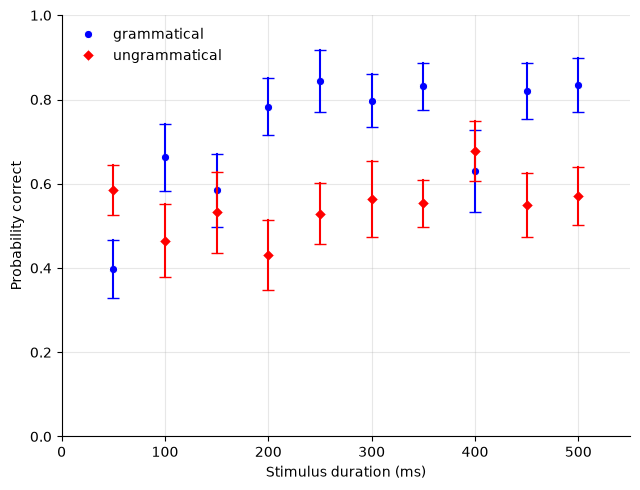

In [146]:
plot_accuracy(df_acc)

In [143]:
# define function for plotting sensitivity and bias (corresponding to original fig 3)
def plot_sdt(df):
    # create fig w/ 2 subplots
    fig, axes = plt.subplots(1, 2, figsize = (10, 5))
    # create left lineplot for sensitivity
    sns.lineplot(data = df, 
                 x = "presentation_duration", 
                 y = "d_prime",
                 color = "blue", 
                 marker = "o", 
                 linestyle = "",
                 errorbar = ("ci", 95),
                 err_style = "bars",
                 err_kws = {"capsize": 4},
                 ax = axes[0])
    axes[0].grid(True, alpha = 0.3)
    # set axis limits
    axes[0].set_xlim(0, 550)
    axes[0].set_ylim(0.0, 4.0)
    # set axis labels
    axes[0].set_xlabel("Stimulus duration (ms)")
    axes[0].set_ylabel("Sensitivity (d')")
    # create right lineplot for bias
    sns.lineplot(data = df, 
                 x = "presentation_duration", 
                 y = "c",
                 color = "blue", 
                 marker = "o", 
                 linestyle = "",
                 errorbar = ("ci", 95),
                 err_style = "bars",
                 err_kws = {"capsize": 4},
                 ax = axes[1])
    # add grid
    axes[1].grid(True, alpha = 0.3)
    # set axis limits
    axes[1].set_xlim(0, 550)
    axes[1].set_ylim(-1, 1)
    # set axis labels
    axes[1].set_xlabel("Stimulus duration (ms)")
    axes[1].set_ylabel("Bias (c)")
    # remove top & right lines
    sns.despine()
    # adjust margins
    plt.tight_layout()
    # save to png
    plt.savefig(os.path.join("..", "out", f"sdt_{ts}.png"), bbox_inches = "tight")
    plt.show()

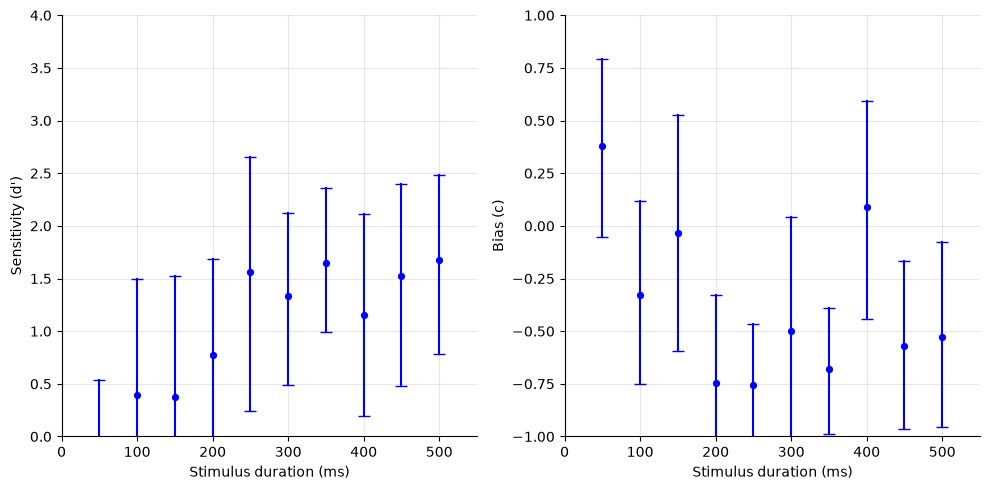

In [144]:
plot_sdt(df_sdt)